# 105장 · RAG 화면의 오류 상태와 안내 문구

근거를 찾지 못했다는 정상 응답과 서버 응답을 끝까지 받지 못한 상태는 다릅니다. 각 상태에서 사용자에게 확실히 말할 수 있는 내용만 표시합니다.

화면의 빨간 안내가 모두 “다시 시도하세요”라면 사용자는 문서에 답이 없어도 같은 질문을 계속 보냅니다. 근거 없음, 권한 확인 필요, 전달 여부 미확인에서 서로 다른 다음 행동을 고릅니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 팀별 변형을 시도한 뒤 해당 셀 아래에서 예시를 펼쳐 비교할 수 있습니다.


## 근거 없음 상태의 결과 카드

Q03의 문안 예시　“현재 허용된 자료로 교체 일정을 확인할 수 없습니다. 담당자에게 근거를 확인하세요.” 처리 자체는 끝났으므로 진행 표시를 끄고 출처를 비웁니다. 다른 사람의 대화를 찾을 수 없는 경우에는 대화가 실제로 존재하는지 드러내지 않고 현재 선택한 대화와 접근 범위를 확인하도록 안내합니다.


### 셀 01 · 근거 없는 결과의 상태 카드

로컬 Q03의 업무 결과를 읽고 다음에 할 행동을 붙여 보세요.


In [1]:
result = {'status': 'no_evidence',
 'answer': '주어진 문서에서 확인할 수 없습니다. 담당자에게 확인하세요.',
 'sources': [],
 'mode': 'local_rule_fixture',
 'model_calls': 0}
if result["status"] == "no_evidence":
    print(result["answer"])
    print("다음 행동 · 담당자에게 근거 확인")

주어진 문서에서 확인할 수 없습니다. 담당자에게 확인하세요.
다음 행동 · 담당자에게 근거 확인


사용자가 규정에서 찾을 수 없는 일정을 어디서 확인할지 알게 됩니다. 검색이 실패했거나 서버가 응답하지 않은 상황과는 안내가 다릅니다.


## 응답 단절과 저장 실패의 구분

권한 오류 문안 예시　“작업을 수행할 권한을 확인하지 못했습니다. 담당자에게 접근 범위를 확인하세요.” 전송 중단 문안 예시　“응답 전달 여부를 확인하지 못했습니다. 저장됐을 수 있으므로 같은 요청 기록을 먼저 확인하세요.” 실제 저장 성공·실패를 모른다면 완료 이력으로 옮기지 않습니다.

<!-- lesson-visual detail-uncertain -->
**응답이 끊기면 저장 실패라고 할 수 있을까요?**

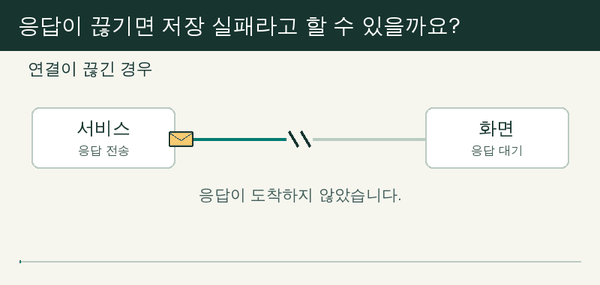

첫 장면의 화면은 결과를 받지 못해 저장 상태를 모릅니다. 다음 장면에서는 failed가 화면에 도착하므로 저장 실패를 알릴 수 있습니다. 전송이 끊기면 같은 요청 기록부터 확인합니다.
<!-- /lesson-visual detail-uncertain -->


### 과제 02 · 선택 연습 · 저장 오류 안내

답은 계산했지만 저장이 실패한 save_failure의 상태를 보고, 다음 행동이 들어간 한 줄을 적으세요.

이 사례의 요청 ID는 save_failure이고 저장 상태는 failed입니다. 오류 코드 storage_failure는 저장 단계의 실패를 뜻합니다. 서버에 요청이 도착했는지조차 모르는 경우와 구분해 화면 문구를 정하세요.


In [2]:
storage_status = "failed"
# 저장 상태에 맞춰 다음 행동을 적으세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>storage_status = &quot;failed&quot;
if storage_status == &quot;failed&quot;:
    print(&quot;계산한 답을 저장하지 못했습니다. 재전송 전에 저장 기록을 확인하세요.&quot;)</code></pre>
<p>실행 결과</p><pre><code>계산한 답을 저장하지 못했습니다. 재전송 전에 저장 기록을 확인하세요.</code></pre>
<p>실패한 대상은 저장입니다. 원문 근거가 없다는 문구를 보여 주거나 자동으로 재전송하면 문제의 위치를 숨기게 됩니다.</p>
</details>


## 돌아보기

106장에는 업무 상태와 오류 상태를 섞지 않는 화면 문구를 넘기세요. 아직 저장된 적이 있는지 모를 때는 자동으로 다시 보내지 않고 요청 ID로 조회하는 경로를 남깁니다.
